<a href="https://colab.research.google.com/github/Bilal-data/diamonds-price-prediction/blob/main/diamonds_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import seaborn as sns

diamonds = sns.load_dataset("diamonds")
print(diamonds.shape)
print(diamonds.head())

(53940, 10)
   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75


In [ ]:
print(diamonds[["carat", "price", "x", "y", "z"]].describe())

              carat         price             x             y             z
count  53940.000000  53940.000000  53940.000000  53940.000000  53940.000000
mean       0.797940   3932.799722      5.731157      5.734526      3.538734
std        0.474011   3989.439738      1.121761      1.142135      0.705699
min        0.200000    326.000000      0.000000      0.000000      0.000000
25%        0.400000    950.000000      4.710000      4.720000      2.910000
50%        0.700000   2401.000000      5.700000      5.710000      3.530000
75%        1.040000   5324.250000      6.540000      6.540000      4.040000
max        5.010000  18823.000000     10.740000     58.900000     31.800000


In [ ]:
zeros = diamonds[(diamonds["x"] == 0) | (diamonds["y"] == 0) | (diamonds["z"] == 0)]
print(len(zeros))

20


In [ ]:
diamonds = diamonds[(diamonds["x"] > 0) & (diamonds["y"] > 0) & (diamonds["z"] > 0)]
print(diamonds.shape)

(53920, 10)


In [ ]:
odd = diamonds[(diamonds["y"] > 20) | (diamonds["z"] > 20)]
print(len(odd))
print(odd[["carat", "price", "x", "y", "z"]])

3
       carat  price     x      y      z
24067   2.00  12210  8.09  58.90   8.06
48410   0.51   1970  5.12   5.15  31.80
49189   0.51   2075  5.15  31.80   5.12


In [ ]:
diamonds = diamonds[(diamonds["y"] < 20) & (diamonds["z"] < 20)]
print(diamonds.shape)

(53917, 10)


In [ ]:
print(diamonds[["carat", "price"]].corr())

          carat     price
carat  1.000000  0.921586
price  0.921586  1.000000


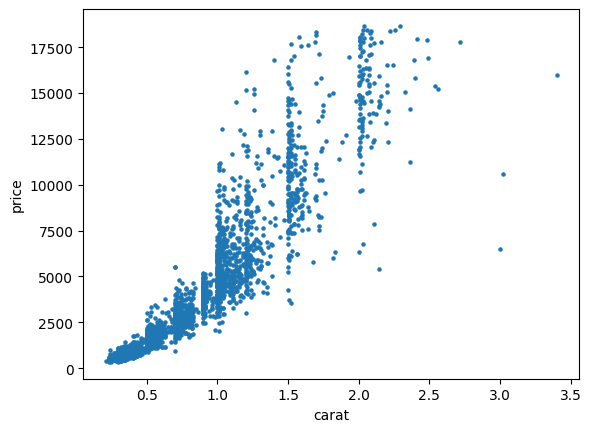

In [ ]:
import matplotlib.pyplot as plt

sample = diamonds.sample(3000, random_state=1)
plt.scatter(sample["carat"], sample["price"], s=5)
plt.xlabel("carat")
plt.ylabel("price")
plt.show()

In [ ]:
print(diamonds.groupby("cut", observed=True)["price"].mean().sort_values())

cut
Ideal        3457.005337
Good         3926.403509
Very Good    3981.830629
Fair         4357.500932
Premium      4579.130779
Name: price, dtype: float64


In [ ]:
print(diamonds.groupby("cut", observed=True)["carat"].mean().sort_values())

cut
Ideal        0.702768
Very Good    0.806390
Good         0.848711
Premium      0.891328
Fair         1.046078
Name: carat, dtype: float64


In [ ]:
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

diamonds = sns.load_dataset("diamonds")
diamonds = diamonds[(diamonds["x"] > 0) & (diamonds["y"] > 0) & (diamonds["z"] > 0)]
diamonds = diamonds[(diamonds["y"] < 20) & (diamonds["z"] < 20)]
print(diamonds.shape)

features = ["carat", "depth", "table", "x", "y", "z"]
X = diamonds[features]
y = diamonds["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
print("Dummy MAE:", mean_absolute_error(y_test, dummy.predict(X_test)))

(53917, 10)
Dummy MAE: 3008.402689259864


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

print("Random Forest MAE:", mean_absolute_error(y_test, rf.predict(X_test)))

Random Forest MAE: 776.3084166477919


In [ ]:
import pandas as pd

cols = ["carat", "depth", "table", "x", "y", "z", "cut", "color", "clarity"]
X2 = pd.get_dummies(diamonds[cols], columns=["cut", "color", "clarity"])

print(X2.shape)
print(list(X2.columns))

(53917, 26)
['carat', 'depth', 'table', 'x', 'y', 'z', 'cut_Ideal', 'cut_Premium', 'cut_Very Good', 'cut_Good', 'cut_Fair', 'color_D', 'color_E', 'color_F', 'color_G', 'color_H', 'color_I', 'color_J', 'clarity_IF', 'clarity_VVS1', 'clarity_VVS2', 'clarity_VS1', 'clarity_VS2', 'clarity_SI1', 'clarity_SI2', 'clarity_I1']


In [ ]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
      X2, y, test_size=0.2, random_state=42
)

rf2 = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf2.fit(X2_train, y2_train)

print("RF with cut/color/clarity MAE:", mean_absolute_error(y2_test, rf2.predict(X2_test)))


RF with cut/color/clarity MAE: 265.65801147606976


In [ ]:
imp = pd.Series(rf2.feature_importances_, index=X2.columns)
print(imp.sort_values(ascending=False).head(8))

carat          0.608900
y              0.276398
clarity_SI2    0.018501
clarity_I1     0.015150
clarity_SI1    0.013817
color_J        0.010703
color_I        0.007887
clarity_VS2    0.007103
dtype: float64
